<a href="https://colab.research.google.com/github/coconutcandy74/ece285-homework1/blob/main/ece285_homework1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import random
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [3]:
%pip -q install kagglehub

In [4]:
import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download(
        "paultimothymooney/chest-xray-pneumonia"
    )
)

print("Download completed!")
print("Data storage location: ", dataset_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Download completed!
Data storage location:  /kaggle/input/chest-xray-pneumonia


In [5]:
train_dirs = [
    p for p in dataset_path.rglob("train")
    if p.is_dir() and (p / "NORMAL").is_dir()
]

if not train_dirs:
    raise FileNotFoundError("Training directory not found.")

DATA_ROOT = min(train_dirs, key=lambda p: len(p.parts)).parent

print("Dataset root:", DATA_ROOT)

image_extensions = {".jpg", ".jpeg", ".png"}

for split in ["train", "val", "test"]:
    print(f"\n{split}:")

    for category in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_ROOT / split / category

        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        )

        print(f"  {category}: {count} images")

Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray

train:
  NORMAL: 1341 images
  PNEUMONIA: 3875 images

val:
  NORMAL: 8 images
  PNEUMONIA: 8 images

test:
  NORMAL: 234 images
  PNEUMONIA: 390 images


In [6]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

IMAGE_SIZE = 64

# Convert images to grayscale, resize them, and convert them to tensors
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

# Load images from the training directory
train_dataset = datasets.ImageFolder(
    root=str(DATA_ROOT / "train"),
    transform=transform
)

print("Number of training images:", len(train_dataset))
print("Classes:", train_dataset.classes)

# Inspect one processed image
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Pixel range:", image.min().item(), "to", image.max().item())

Number of training images: 5216
Classes: ['NORMAL', 'PNEUMONIA']
Image shape: torch.Size([1, 64, 64])
Pixel range: 0.0 to 0.9490196108818054


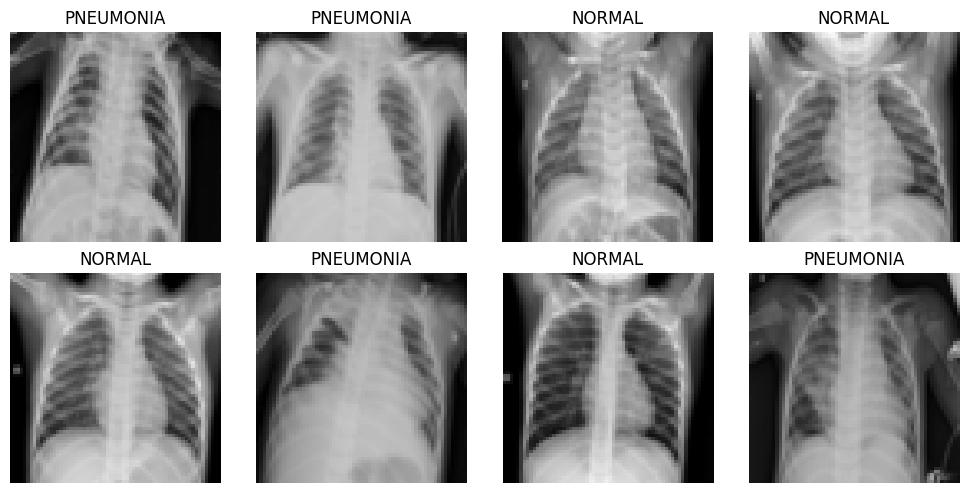

In [7]:
# Select random images using a fixed seed
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(
    len(train_dataset),
    generator=generator
)[:8].tolist()

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for ax, index in zip(axes.flat, indices):
    image, label = train_dataset[index]

    # Remove the channel dimension for display
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(train_dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from torch.utils.data import DataLoader, random_split

SEED = 42
BATCH_SIZE = 64

# Split the original training set into training and validation subsets
num_val = round(0.1 * len(train_dataset))
num_train = len(train_dataset) - num_val

train_subset, val_subset = random_split(
    train_dataset,
    [num_train, num_val],
    generator=torch.Generator().manual_seed(SEED)
)

# Load the original test set for final evaluation
test_dataset = datasets.ImageFolder(
    root=str(DATA_ROOT / "test"),
    transform=transform
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_dataset))

Training images: 4694
Validation images: 522
Test images: 624


In [9]:
# Select the available device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": 2,
    "pin_memory": device.type == "cuda",
}

# Shuffle training images before each epoch
train_loader = DataLoader(
    train_subset,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    **loader_kwargs
)

# Keep validation and test images in a fixed order
val_loader = DataLoader(
    val_subset,
    shuffle=False,
    **loader_kwargs
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_kwargs
)

# Inspect one training batch
images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Number of training batches:", len(train_loader))
print("Device for training:", device)

Batch shape: torch.Size([64, 1, 64, 64])
Number of training batches: 74
Device for training: cuda


In [10]:
import torch.nn as nn

LATENT_DIM = 64

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.latent_dim = latent_dim

        # Reduce the spatial size from 64x64 to 4x4
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Flatten()
        )

        # Predict the mean and log variance of the latent distribution
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)

        # Map the latent vector back to a feature map
        self.decoder_input = nn.Linear(latent_dim, 256 * 4 * 4)

        # Increase the spatial size from 4x4 to 64x64
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                256, 128, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                128, 64, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 32, kernel_size=4, stride=2, padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 1, kernel_size=4, stride=2, padding=1
            ),
            nn.Sigmoid()
        )

    def encode(self, x):
        features = self.encoder(x)
        mu = self.fc_mu(features)
        logvar = self.fc_logvar(features)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        # Convert log variance to standard deviation
        std = torch.exp(0.5 * logvar)

        # Sample standard normal noise
        eps = torch.randn_like(std)

        return mu + std * eps

    def decode(self, z):
        features = self.decoder_input(z)
        features = features.reshape(-1, 256, 4, 4)
        return self.decoder(features)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar

In [11]:
# Set the seed before initializing model parameters
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Move the model to the selected device
model = ConvVAE(latent_dim=LATENT_DIM).to(device)

# Run one batch through the model without computing gradients
model.eval()

with torch.no_grad():
    x = images.to(device)
    reconstruction, mu, logvar = model(x)

print("Input shape:", x.shape)
print("Reconstruction shape:", reconstruction.shape)
print("Mean shape:", mu.shape)
print("Log variance shape:", logvar.shape)
print("Model device:", next(model.parameters()).device)

Input shape: torch.Size([64, 1, 64, 64])
Reconstruction shape: torch.Size([64, 1, 64, 64])
Mean shape: torch.Size([64, 64])
Log variance shape: torch.Size([64, 64])
Model device: cuda:0


In [12]:
import torch.nn.functional as F

def vae_loss(reconstruction, x, mu, logvar):
    batch_size = x.size(0)

    # Sum over pixels and average over images
    recon_loss = F.binary_cross_entropy(
        reconstruction,
        x,
        reduction="sum"
    ) / batch_size

    # Sum over latent dimensions and average over images
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    ) / batch_size

    total_loss = recon_loss + kl_loss

    return total_loss, recon_loss, kl_loss

In [13]:
import json
from pathlib import Path
from tqdm.auto import tqdm

EPOCHS = 30
LEARNING_RATE = 1e-3

OUTPUT_DIR = Path.cwd() / "vae_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

def run_epoch(loader, training):
    # Enable training mode or evaluation mode
    model.train(training)

    totals = {
        "loss": 0.0,
        "recon": 0.0,
        "kl": 0.0
    }
    num_images = 0

    description = "Training" if training else "Validation"

    for batch_images, _ in tqdm(
        loader,
        desc=description,
        leave=False
    ):
        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        # Compute gradients only during training
        with torch.set_grad_enabled(training):
            reconstruction, mu, logvar = model(batch_images)

            loss, recon_loss, kl_loss = vae_loss(
                reconstruction,
                batch_images,
                mu,
                logvar
            )

            if training:
                loss.backward()
                optimizer.step()

        # Weight batch averages by the actual batch size
        batch_size = batch_images.size(0)
        num_images += batch_size

        totals["loss"] += loss.item() * batch_size
        totals["recon"] += recon_loss.item() * batch_size
        totals["kl"] += kl_loss.item() * batch_size

    return {
        name: value / num_images
        for name, value in totals.items()
    }


history = []
best_val_loss = float("inf")
best_epoch = None

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    # Record all loss components for later plotting
    record = {"epoch": epoch}

    for name, value in train_metrics.items():
        record[f"train_{name}"] = value

    for name, value in val_metrics.items():
        record[f"val_{name}"] = value

    history.append(record)

    # Save the model with the lowest validation total loss
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": best_val_loss,
                "latent_dim": LATENT_DIM,
                "image_size": IMAGE_SIZE,
                "batch_size": BATCH_SIZE,
                "learning_rate": LEARNING_RATE,
                "seed": SEED,
                "train_indices": train_subset.indices,
                "val_indices": val_subset.indices,
            },
            OUTPUT_DIR / "best_vae.pt"
        )

    # Save the training history after every epoch
    with open(OUTPUT_DIR / "history.json", "w") as f:
        json.dump(history, f, indent=2)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train: {train_metrics['loss']:.2f} "
        f"(Recon: {train_metrics['recon']:.2f}, "
        f"KL: {train_metrics['kl']:.2f}) | "
        f"Val: {val_metrics['loss']:.2f} "
        f"(Recon: {val_metrics['recon']:.2f}, "
        f"KL: {val_metrics['kl']:.2f})"
    )

print("\nTraining complete!")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.2f}")
print("Saved files:", OUTPUT_DIR)

Training:   0%|          | 0/74 [00:00<?, ?it/s]

Validation:   0%|          | 0/9 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1d3854dbc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Epoch 01/30 | Train: 2605.61 (Recon: 2595.06, KL: 10.55) | Val: 2496.32 (Recon: 2481.56, KL: 14.77)


Training:   0%|          | 0/74 [00:00<?, ?it/s]

...

Epoch 29/30 | Train: 2391.58 (Recon: 2368.78, KL: 22.80) | Val: 2390.10 (Recon: 2367.34, KL: 22.75)


Training:   0%|          | 0/74 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1d3854dbc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c1d3854dbc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 30/30 | Train: 2391.40 (Recon: 2368.57, KL: 22.83) | Val: 2394.58 (Recon: 2371.74, KL: 22.83)

Training complete!
Best epoch: 29
Best validation loss: 2390.10
Saved files: /content/vae_outputs


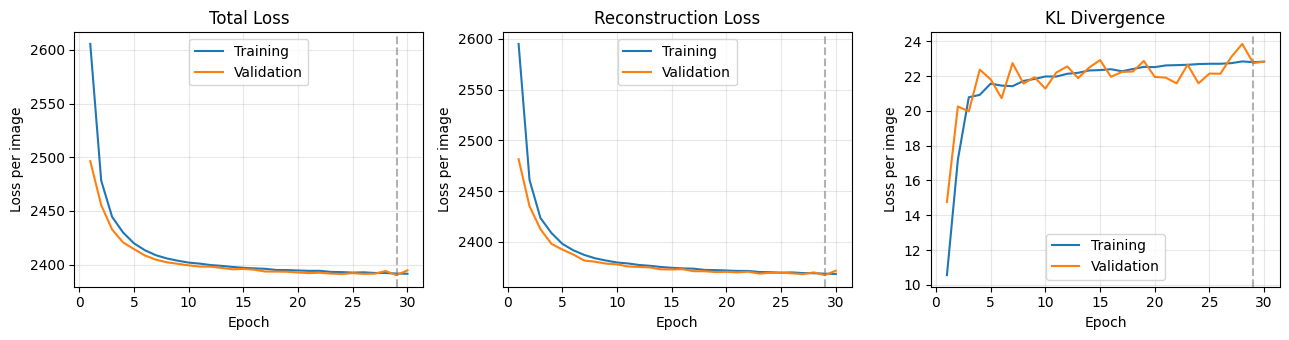

Loaded checkpoint from epoch: 29


In [14]:
# Load the checkpoint with the lowest validation loss
checkpoint = torch.load(
    OUTPUT_DIR / "best_vae.pt",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Load the saved training history
with open(OUTPUT_DIR / "history.json", "r") as f:
    history = json.load(f)

epochs = [record["epoch"] for record in history]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

metrics = [
    ("loss", "Total Loss"),
    ("recon", "Reconstruction Loss"),
    ("kl", "KL Divergence")
]

for ax, (key, title) in zip(axes, metrics):
    ax.plot(
        epochs,
        [record[f"train_{key}"] for record in history],
        label="Training"
    )
    ax.plot(
        epochs,
        [record[f"val_{key}"] for record in history],
        label="Validation"
    )

    ax.axvline(
        checkpoint["epoch"],
        color="gray",
        linestyle="--",
        alpha=0.6
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss per image")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Loaded checkpoint from epoch:", checkpoint["epoch"])

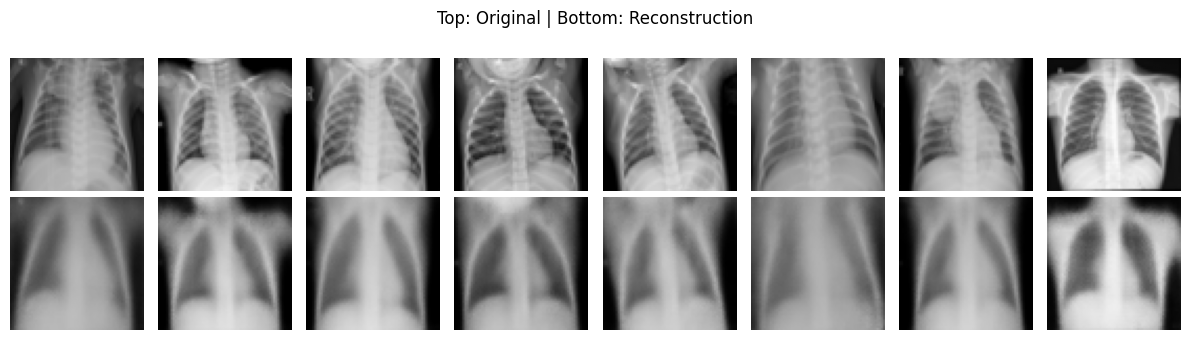

In [15]:
# Select the first eight validation images
val_images, _ = next(iter(val_loader))
originals = val_images[:8].to(device)

with torch.no_grad():
    # Use the latent mean for a deterministic reconstruction
    mu, _ = model.encode(originals)
    reconstructions = model.decode(mu)

originals = originals.cpu()
reconstructions = reconstructions.cpu()

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))

for i in range(8):
    axes[0, i].imshow(
        originals[i, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].imshow(
        reconstructions[i, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, i].axis("off")
    axes[1, i].axis("off")

fig.suptitle("Top: Original | Bottom: Reconstruction")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

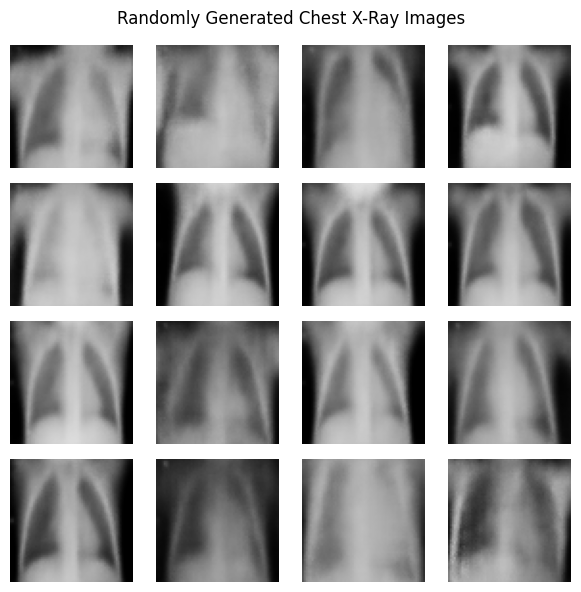

Figures saved to: /content/vae_outputs


In [16]:
# Use a fixed seed to make the generated examples reproducible
sample_generator = torch.Generator().manual_seed(123)

with torch.no_grad():
    z = torch.randn(
        16,
        checkpoint["latent_dim"],
        generator=sample_generator
    ).to(device)

    generated_images = model.decode(z).cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

fig.suptitle("Randomly Generated Chest X-Ray Images")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "generated_samples.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Figures saved to:", OUTPUT_DIR)

In [17]:
%pip -q install pytorch-ignite pytorch-fid scipy

In [18]:
import ignite
import torchvision

from ignite.metrics import FID, InceptionScore
from pytorch_fid.inception import InceptionV3
from torchvision.models import inception_v3, Inception_V3_Weights

# Extract the 2048-dimensional features used for FID
class FIDFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()

        block_index = InceptionV3.BLOCK_INDEX_BY_DIM[2048]
        self.network = InceptionV3(
            output_blocks=[block_index],
            resize_input=True,
            normalize_input=True
        )

    def forward(self, x):
        return self.network(x)[0].flatten(1)


fid_extractor = FIDFeatureExtractor().to(device).eval()

fid_metric = FID(
    num_features=2048,
    feature_extractor=fid_extractor,
    device=device
)

# Prepare the ImageNet classifier and its official preprocessing for IS
is_weights = Inception_V3_Weights.IMAGENET1K_V1

is_classifier = inception_v3(
    weights=is_weights,
    transform_input=False
).to(device).eval()

is_preprocess = is_weights.transforms()

# Feed classification probabilities directly into the IS metric
is_metric = InceptionScore(
    num_features=1000,
    feature_extractor=nn.Identity(),
    device=device
)

print("Evaluation models are ready.")

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 120MB/s]


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:01<00:00, 82.5MB/s] 


Evaluation models are ready.


In [19]:
# Reload the best VAE checkpoint
checkpoint = torch.load(
    OUTPUT_DIR / "best_vae.pt",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Use smaller batches for the evaluation networks
eval_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=device.type == "cuda"
)

EVAL_SEED = 2026
eval_generator = torch.Generator().manual_seed(EVAL_SEED)

fid_metric.reset()
is_metric.reset()
num_evaluated = 0

with torch.no_grad():
    for real_images, _ in tqdm(eval_loader, desc="Evaluating"):
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # Generate new images from the standard normal prior
        z = torch.randn(
            batch_size,
            checkpoint["latent_dim"],
            generator=eval_generator
        ).to(device)

        fake_images = model.decode(z)

        # Repeat the grayscale channel to create three-channel inputs
        real_rgb = real_images.repeat(1, 3, 1, 1)
        fake_rgb = fake_images.repeat(1, 3, 1, 1)

        # The FID extractor handles resizing and normalization internally
        fid_metric.update((fake_rgb, real_rgb))

        # Apply the classifier preprocessing and compute probabilities
        logits = is_classifier(is_preprocess(fake_rgb))
        probabilities = torch.softmax(logits, dim=1)

        is_metric.update(probabilities)
        num_evaluated += batch_size

print("Computing final scores...")

fid_value = float(fid_metric.compute())
is_value = float(is_metric.compute())

results = {
    "checkpoint_epoch": checkpoint["epoch"],
    "num_real_images": num_evaluated,
    "num_generated_images": num_evaluated,
    "evaluation_seed": EVAL_SEED,
    "fid": fid_value,
    "inception_score": is_value,
    "fid_features": "pytorch-fid InceptionV3, 2048 dimensions",
    "is_classifier": "torchvision InceptionV3, IMAGENET1K_V1",
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "ignite_version": str(ignite.__version__)
}

with open(OUTPUT_DIR / "evaluation_results.json", "w") as f:
    json.dump(results, f, indent=2)

print(f"Real images: {num_evaluated}")
print(f"Generated images: {num_evaluated}")
print(f"FID: {fid_value:.4f}")
print(f"Inception Score: {is_value:.4f}")
print("Results saved to:", OUTPUT_DIR / "evaluation_results.json")

Evaluating:   0%|          | 0/20 [00:00<?, ?it/s]

Computing final scores...
Real images: 624
Generated images: 624
FID: 279.1498
Inception Score: 1.7643
Results saved to: /content/vae_outputs/evaluation_results.json


In [20]:
import shutil
from google.colab import files

# Package the checkpoint, figures, training history, and evaluation results
archive_path = shutil.make_archive(
    base_name=str(OUTPUT_DIR.parent / "vae_results"),
    format="zip",
    root_dir=str(OUTPUT_DIR)
)

print("Archive created:", archive_path)

# Download the archive to your computer
files.download(archive_path)

Archive created: /content/vae_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>